# Atelier ML - Analyse d'image : classification

Objectif : entraîner un **réseau de neurones convolutif** (CNN) à reconnaître des vêtements à partir d'images de 28 x 28 pixels, avec le jeu de données **Fashion-MNIST** de Zalando.

## Modules utilisés

- **Pandas** : chargement des fichiers CSV
- **NumPy** : manipulation des tableaux de pixels
- **matplotlib** : affichage des images et des graphiques
- **scikit-learn** : découpage en données d'apprentissage et de validation
- **TensorFlow / Keras** : création et entraînement du réseau de neurones

`tf.config.set_visible_devices([], 'GPU')` force l'utilisation du processeur (CPU) au lieu de la carte graphique.

In [1]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

#Définition de la longueur et de la largeur de l'image
LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

#Chargement des images
observations_entrainement = pnd.read_csv('datas/fashion-mnist_train.csv')

## De quelles données disposons-nous ?

Il n'y a pas de fichiers JPEG ou PNG : chaque image est une **ligne** du fichier CSV.

- 60 000 images d'apprentissage et 10 000 images de test
- chaque image fait 28 x 28 = **784 pixels**
- chaque pixel est une valeur de luminosité entre 0 et 255
- la première colonne (`label`) est le type de vêtement, les 784 autres sont les pixels

| Label | Vêtement |
|---|---|
| 0 | T-shirt/haut |
| 1 | Pantalon |
| 2 | Pull |
| 3 | Robe |
| 4 | Manteau |
| 5 | Sandales |
| 6 | Chemise |
| 7 | Baskets |
| 8 | Sac |
| 9 | Bottes de cheville |

In [2]:
print(observations_entrainement.shape)
print(observations_entrainement.head())

(60000, 785)
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      9       0       0       0       0       0       0       0       0   
1      0       0       0       0       0       0       1       0       0   
2      0       0       0       0       0       0       0       0       0   
3      3       0       0       0       0       0       0       0       0   
4      0       0       0       0       0       0       0       0       0   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0       0  ...         0         0         0         0         0         0   
1       0  ...       119       114       130        76         0         0   
2       0  ...         0         0         1         0         0         0   
3      33  ...         0         0         0         0         0         0   
4       0  ...         0         0         0         0         0         0   

   pixel781  pixel782  pixel783  pixel784  
0         0      

## Affichage de la première image

On exclut la première colonne (les labels) pour garder seulement les pixels, puis on remet les 784 pixels de la première image en forme de carré 28 x 28 avec `reshape` pour l'afficher.

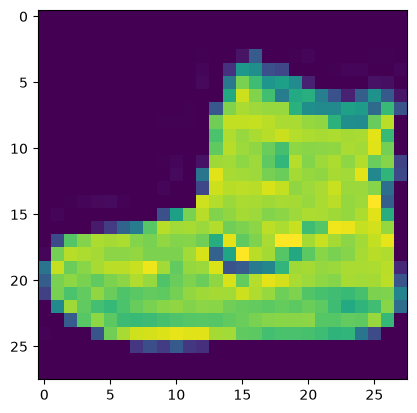

In [3]:
#On exclut la première colonne (les labels) pour constituer un tableau de pixels
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

La première image est une botte de cheville (label 9). Les données ont été récupérées depuis la source officielle de Keras (`keras.datasets.fashion_mnist`) et converties au format CSV du cours : ce sont les mêmes images, seul l'ordre diffère (dans le cours, la première image est un pull).

## Préparation des données d'apprentissage

`to_categorical` transforme chaque label en un tableau de 10 valeurs avec un 1 à la position de la catégorie :

- label 2 (pull) → `[0,0,1,0,0,0,0,0,0,0]`
- label 9 (bottes) → `[0,0,0,0,0,0,0,0,0,1]`

On découpe ensuite les 60 000 images : **80 %** pour l'apprentissage (48 000) et **20 %** pour la validation (12 000).

In [4]:
#On crée des catégories à l'aide du module Keras
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))
#Répartition des données d'entrainement en données d'apprentissage et données de validation
#80% de donnée d'apprentissage et 20% de donnée de validation
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

On remet chaque image au format 28 x 28 x 1 (1 seule couche, car les images sont en niveaux de gris), puis on fait une **mise à l'échelle** (*scaling*) : on divise chaque pixel par 255 pour avoir des valeurs entre 0 et 1. Même traitement pour les données de validation.

In [5]:
# On redimensionne les images au format 28*28 et on réalise un scaling sur les données des pixels
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], 
                                          LARGEUR_IMAGE, 
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], 
                                    LARGEUR_IMAGE, 
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

print(X_apprentissage.shape, X_validation.shape)

(48000, 28, 28, 1) (12000, 28, 28, 1)


## Préparation des données de tests

Les 10 000 images de test servent à vérifier l'efficacité du modèle sur des images qu'il n'a jamais vues. Elles sont préparées exactement comme les données d'apprentissage.

In [6]:
#Preparation des données de tests
observations_test = pnd.read_csv('datas/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], 
                        LARGEUR_IMAGE, 
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

print(X_test.shape, y_test.shape)

(10000, 28, 28, 1) (10000, 10)


## Un réseau avec une seule couche de convolution

Configuration du premier réseau :

1. une couche de **convolution** : 32 filtres de 3 x 3 qui parcourent l'image pour en extraire des caractéristiques, avec une activation **ReLU** (remplace les valeurs négatives par 0)
2. un **MaxPooling** de 2 x 2 : réduit l'image en gardant la valeur maximale de chaque fenêtre
3. un **Dropout** de 20 % : ignore des neurones au hasard pendant l'apprentissage pour éviter le surapprentissage
4. un **Flatten** : met à plat les images en une seule ligne pour le réseau de neurones
5. une couche de **128 neurones** avec activation ReLU
6. une couche de sortie de **10 neurones** avec activation **Softmax** : une probabilité pour chacune des 10 catégories de vêtements

In [7]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#1- Ajout de la couche de convolution comportant
# 32 filtres de de taille 3x3 (Kernel) parcourant l'image
# Une fonction d'activation de type ReLU (Rectified Linear Activation)
# Une image d'entrée de 28px * 28 px 
reseauNeurone1Convolution.add(Conv2D(32, 
                                     kernel_size=(3, 3), 
                                     activation='relu'))

#2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2 px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

#3- Ajout d'une fonction d'ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#5 - On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

#6 - Ajout d'un réseau de neurones composé de 128 neurones avec 
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#7 - Ajout d'un réseau de neurones composé de 10 neurones avec une 
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

## Compilation, apprentissage et test

La compilation précise :

- la fonction de minimisation de l'erreur (`categorical_crossentropy`)
- l'optimiseur **Adam** (méthode de descente de gradient)
- la valeur mesurée : la précision (`accuracy`)

In [8]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

Paramètres de l'apprentissage :

- **10 epochs** : 10 passages complets des images dans le réseau
- **batch_size = 256** : les images sont envoyées par paquets de 256. Pour 48 000 images, une epoch fait donc 48 000 / 256 = **187 itérations**.
- **verbose = 1** : affiche la progression
- validation sur les 20 % de données de validation

In [9]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8054 - loss: 0.5524 - val_accuracy: 0.8612 - val_loss: 0.3986
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8719 - loss: 0.3654 - val_accuracy: 0.8752 - val_loss: 0.3490
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8865 - loss: 0.3196 - val_accuracy: 0.8882 - val_loss: 0.3167
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8961 - loss: 0.2949 - val_accuracy: 0.8883 - val_loss: 0.3084
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9034 - loss: 0.2739 - val_accuracy: 0.8977 - val_loss: 0.2877
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9082 - loss: 0.2563 - val_accuracy: 0.8994 - val_loss: 0.2790
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9128 - loss: 0.2410 - val_accuracy: 0.8997 - val_loss: 0.2819
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9162 - loss: 0.2299 - val_accuracy: 0.

Évaluation du modèle sur les 10 000 images de test, qu'il n'a jamais vues :

In [10]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.26557639241218567
Précision: 0.9034000039100647


Courbes de la précision et de l'erreur après chaque epoch :

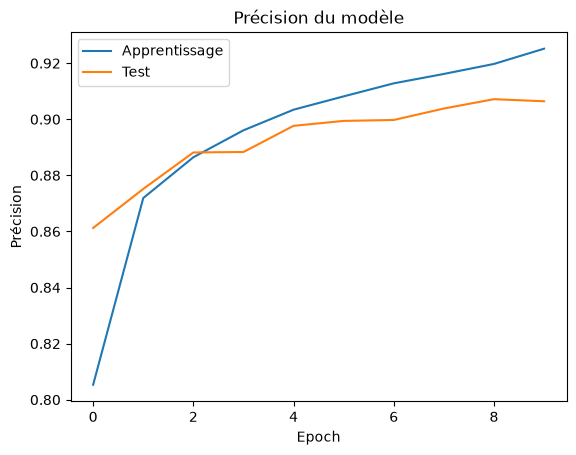

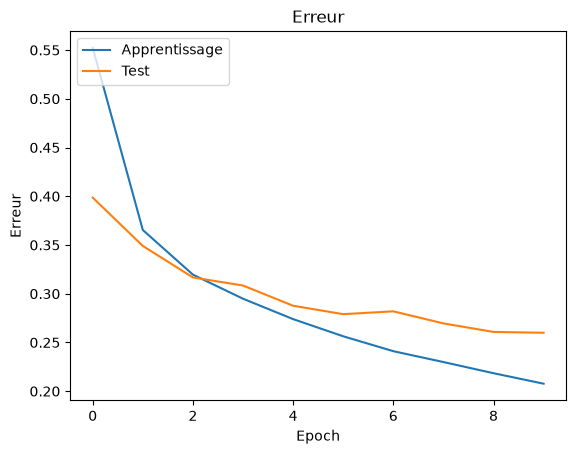

In [11]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
# Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

## Augmentation du nombre de données

Le jeu de test peut contenir des images différentes de celles du jeu d'apprentissage (vêtement un peu tourné, décalé, zoomé...). Pour que le modèle s'y habitue, on **génère de nouvelles images** à partir des images existantes avec `ImageDataGenerator` :

- `rotation_range` : rotation de l'image (en degrés, entre 0 et 180)
- `width_shift_range` et `height_shift_range` : décalage horizontal et vertical
- `shear_range` : cisaillement (l'image est « penchée »)
- `zoom_range` : zoom

In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08)

On relance l'apprentissage avec les images générées :

- **50 epochs** au lieu de 10, car on dispose de beaucoup plus d'images
- `fit` avec un générateur est une boucle sans fin : `steps_per_epoch = 48000 // 256` (187 itérations) indique quand passer à l'epoch suivante

Cet apprentissage est beaucoup plus long, car de nouvelles images sont générées à chaque paquet.

In [13]:
nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.8252 - loss: 0.4673 - val_accuracy: 0.8352 - val_loss: 0.4352
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8555 - loss: 0.4010

c:\Users\Tommy1\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8555 - loss: 0.4010 - val_accuracy: 0.8391 - val_loss: 0.4303
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8457 - loss: 0.4122 - val_accuracy: 0.8460 - val_loss: 0.4142
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8672 - loss: 0.3886 - val_accuracy: 0.8454 - val_loss: 0.4146
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8522 - loss: 0.3938 - val_accuracy: 0.8639 - val_loss: 0.3785
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8594 - loss: 0.3628 - val_accuracy: 0.8599 - val_loss: 0.3825
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8601 - loss: 0.3738 - val_accuracy: 0.8596 - val_loss: 0.3825
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8320 - loss: 0.4621 - val_accuracy: 0.8651 - val_loss: 0.3737
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8652 - loss: 0.3642 - val_accuracy: 0.8682 - 

Précision d'environ **0.91** sur les images de test (le cours obtient 0.9175) : un peu mieux qu'avec le premier apprentissage. Le modèle a vu plus de variantes de chaque vêtement, il reconnaît donc mieux des images qu'il n'a jamais vues.

Le résultat varie un peu à chaque exécution, car les images générées sont aléatoires.

## Sauvegarde du modèle

On sauvegarde le modèle dans le dossier `modele/` pour l'utiliser dans `test_model.ipynb` :

- `modele.json` : la description du réseau (ses couches)
- `modele.weights.h5` : les poids appris pendant l'entraînement

In [14]:
#Sauvegarde du modèle
# Serialisation du modèle 
model_json = reseauNeurone1Convolution.to_json() 
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)

# Serialisation des poids
reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !
